# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 5b: TextCNN - Skema 2 "Tokenizer"
Tokenizer subword IndoBERT -> embedding layer IndoBERT 768-dim (frozen) -> Conv1D (kernel 3/4/5, DILATIH) -> max-over-time -> Dropout -> Fully Connected -> softmax

Yang dibekukan hanya embedding layer; Conv1d dan Linear tetap dilatih.  
Arsitektur dan hyperparameter sama dengan Part 05a, sehingga beda hasil berasal dari tokenizer + embedding.

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`, `utils_embedding.py`
- Output: `outputs/textcnn_tokenizer_val_results.json`, `outputs/models/textcnn_tokenizer.pt`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [1]:
import os, json, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                            classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Fungsi Skema 2 (tokenizer subword + embedding frozen IndoBERT); utils_embedding.py
from utils_embedding import MODEL_NAME, get_device, load_tokenizer_and_frozen_embedding, encode_subword

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/textcnn_tokenizer_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Skema 2: tokenizer subword + embedding layer IndoBERT pre-trained (frozen). Lihat utils_embedding.py
MAX_LEN = 128 # panjang maksimum dalam token subword; lihat persentase terpotong di Step 2

# Hyperparameter tetap, sama dengan versi Skema 1 (tanpa tuning)
NUM_FILTERS = 100 # jumlah filter per ukuran kernel
KERNEL_SIZES = (3, 4, 5) # n-gram 3, 4, 5 token
DROPOUT = 0.5
BATCH_SIZE = 64
EPOCHS = 15
LR = 1e-3 # Adam

for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
NUM_CLASSES = len(labels)
assert all(label_map[l] == i for i, l in enumerate(labels))
y_train = torch.tensor([label_map[l] for l in train_df[LABEL_COL]], dtype=torch.long)
y_val = torch.tensor([label_map[l] for l in val_df[LABEL_COL]], dtype=torch.long)
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenizer subword IndoBERT & embedding layer frozen
Tokenizer dan tabel embedding diambil dari `indobenchmark/indobert-base-p1`.  
Hanya saja encoder transformer-nya tidak dipakai.

In [2]:
tokenizer, emb_layer = load_tokenizer_and_frozen_embedding(MODEL_NAME)
PAD_ID = tokenizer.pad_token_id
print(f"Checkpoint: {MODEL_NAME} | vocab subword: {tokenizer.vocab_size} | embedding: {tuple(emb_layer.weight.shape)}")
print("Embedding beku (requires_grad):", emb_layer.weight.requires_grad)
assert not emb_layer.weight.requires_grad

contoh = train_df[TEXT_COL].iloc[0]
print("\nContoh teks :", contoh[:80])
print("Subword:", tokenizer.tokenize(contoh)[:12])

X_train, M_train = encode_subword(train_df[TEXT_COL].tolist(), tokenizer, MAX_LEN)
X_val, M_val = encode_subword(val_df[TEXT_COL].tolist(), tokenizer, MAX_LEN)

# Berapa banyak teks terpotong? (cek panjang subword asli di train)
len_full = np.array([len(x) for x in tokenizer(train_df[TEXT_COL].tolist(), add_special_tokens=False)["input_ids"]])
print(f"Panjang subword train: rata-rata {len_full.mean():.1f} | persentil 95 = {np.percentile(len_full, 95):.0f} | maks = {len_full.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {(len_full > MAX_LEN).mean()*100:.2f}%")
print("Bentuk tensor -> X_train:", tuple(X_train.shape), "| X_val:", tuple(X_val.shape))

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Checkpoint: indobenchmark/indobert-base-p1 | vocab subword: 30521 | embedding: (50000, 768)
Embedding beku (requires_grad): False

Contoh teks : 365. kalau mau gestun limit kamu di spaylater, gopay coin, gopaylater, akulaku, 
Subword: ['365', '.', 'kalau', 'mau', 'ges', '##tu', '##n', 'limit', 'kamu', 'di', 'spa', '##yl']


model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Panjang subword train: rata-rata 22.5 | persentil 95 = 59 | maks = 86
Teks train yang terpotong oleh MAX_LEN=128: 0.00%
Bentuk tensor -> X_train: (4921, 128) | X_val: (1055, 128)


In [3]:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=256, shuffle=False)

### Step 3 - Arsitektur TextCNN

In [4]:
class TextCNNFrozenEmb(nn.Module):
    def __init__(self, frozen_emb, pad_id, num_classes, num_filters, kernel_sizes, dropout):
        super().__init__()
        # Skema 2: embedding layer IndoBERT pre-trained, frozen (tidak ikut dilatih)
        self.embedding = frozen_emb
        self.pad_id = pad_id
        in_dim = frozen_emb.embedding_dim
        self.convs = nn.ModuleList([nn.Conv1d(in_dim, num_filters, k) for k in kernel_sizes]) # Ditraining
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), num_classes) # Ditraining

    def forward(self, x): # x: (B, L) id subword IndoBERT
        e = self.embedding(x) * (x != self.pad_id).unsqueeze(-1) # padding dinolkan
        e = e.transpose(1, 2) # (B, 768, L)
        feats = [F.relu(conv(e)).max(dim=2).values for conv in self.convs]
        h = self.dropout(torch.cat(feats, dim=1))
        return self.fc(h)

model = TextCNNFrozenEmb(emb_layer, PAD_ID, NUM_CLASSES, NUM_FILTERS, KERNEL_SIZES, DROPOUT).to(device)
w0 = model.embedding.weight.detach().clone() # untuk bukti bahwa embedding tidak berubah
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
VOCAB_SIZE, EMB_DIM = emb_layer.num_embeddings, emb_layer.embedding_dim

with torch.no_grad():
    out = model(X_train[:4].to(device))
assert out.shape == (4, NUM_CLASSES)
print("Forward pass OK -> output:", tuple(out.shape))
print(f"Parameter yang dilatih (conv + fc saja): {n_params:,} | parameter embedding beku: {model.embedding.weight.numel():,}")
print("Embedding trainable:", model.embedding.weight.requires_grad)

Forward pass OK -> output: (4, 6)
Parameter yang dilatih (conv + fc saja): 923,706 | parameter embedding beku: 38,400,000
Embedding trainable: False


### Step 4 - Training (satu run, tetap 15 epoch, model epoch terakhir yang dievaluasi)
Loss: `CrossEntropyLoss` (tanpa class weight). Optimizer Adam lr 1e-3.  
Tidak memilih epoch terbaik di validation, supaya validation tidak dipakai untuk seleksi.  
Kurva menunjukkan jika terjadi overfitting.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR) # hanya parameter yang dilatih

def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward()
                optimizer.step()
            tot_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
print(f"Selesai dalam {time.time()-t0:.0f} detik")

torch.save(model.state_dict(), f"{MODEL_DIR}/textcnn_tokenizer.pt")

Epoch  1/15 | train loss 1.5327 acc 0.4316 | val loss 1.1763 acc 0.6313
Epoch  2/15 | train loss 0.9940 acc 0.6710 | val loss 0.8891 acc 0.6834
Epoch  3/15 | train loss 0.8010 acc 0.7338 | val loss 0.8128 acc 0.7128
Epoch  4/15 | train loss 0.6897 acc 0.7582 | val loss 0.7857 acc 0.7090
Epoch  5/15 | train loss 0.6162 acc 0.7885 | val loss 0.7551 acc 0.7242
Epoch  6/15 | train loss 0.5315 acc 0.8214 | val loss 0.7374 acc 0.7261
Epoch  7/15 | train loss 0.4700 acc 0.8484 | val loss 0.7402 acc 0.7232
Epoch  8/15 | train loss 0.4031 acc 0.8734 | val loss 0.7270 acc 0.7384
Epoch  9/15 | train loss 0.3558 acc 0.8921 | val loss 0.7314 acc 0.7384
Epoch 10/15 | train loss 0.2991 acc 0.9126 | val loss 0.7210 acc 0.7412
Epoch 11/15 | train loss 0.2560 acc 0.9360 | val loss 0.7277 acc 0.7384
Epoch 12/15 | train loss 0.2294 acc 0.9433 | val loss 0.7361 acc 0.7403
Epoch 13/15 | train loss 0.1928 acc 0.9551 | val loss 0.7348 acc 0.7308
Epoch 14/15 | train loss 0.1703 acc 0.9624 | val loss 0.7534 acc

In [6]:
# Bukti: embedding Skema 2 benar-benar frozen (bobotnya identik dengan sebelum training)
same = torch.equal(w0, model.embedding.weight.detach())
print("Embedding identik dengan sebelum training (frozen):", same)
assert same

Embedding identik dengan sebelum training (frozen): True


### Step 5 - Kurva training vs validation (loss & accuracy)

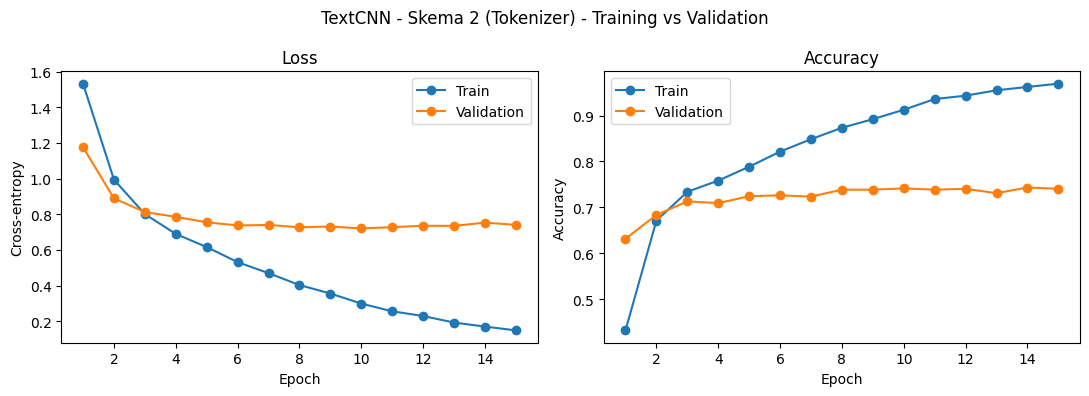

Val loss terendah di epoch 10 (0.7210); epoch terakhir: 0.7405


In [7]:
ep_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep_axis, history["train_loss"], "o-", label="Train")
axes[0].plot(ep_axis, history["val_loss"], "o-", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(ep_axis, history["train_acc"], "o-", label="Train")
axes[1].plot(ep_axis, history["val_acc"], "o-", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("TextCNN - Skema 2 (Tokenizer) - Training vs Validation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05b_textcnn_tokenizer_curves.png", dpi=150)
plt.show()

best_ep = int(np.argmin(history["val_loss"])) + 1
print(f"Val loss terendah di epoch {best_ep} ({min(history['val_loss']):.4f}); epoch terakhir: {history['val_loss'][-1]:.4f}")

### Step 6 - Evaluasi di validation set (model epoch terakhir)

In [8]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in val_loader:
        preds.append(model(xb.to(device)).argmax(1).cpu())
pred_idx = torch.cat(preds).numpy()

y_val_str = val_df[LABEL_COL].values
y_pred_str = np.array([labels[i] for i in pred_idx])

acc = accuracy_score(y_val_str, y_pred_str)
macro_p = precision_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_r = recall_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_f1 = f1_score(y_val_str, y_pred_str, average="macro")

kelas_terbanyak = train_df[LABEL_COL].value_counts().idxmax()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {(val_df[LABEL_COL] == kelas_terbanyak).mean():.4f}")
print(f"TextCNN - Skema 2 (Tokenizer) (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val_str, y_pred_str, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val_str)] # accuracy ditulis di kolom f1-score (konvensi sklearn)
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
TextCNN - Skema 2 (Tokenizer) (val): accuracy = 0.7403 | macro-F1 = 0.7492


,precision,recall,f1-score,support
anger,0.775,0.7381,0.7561,168
fear,0.8,0.7941,0.7970,136
joy,0.7798,0.6931,0.7339,189
love,0.6483,0.8319,0.7287,113
neutral,0.6966,0.6779,0.6871,298
sad,0.7771,0.8079,0.7922,151
accuracy,,,0.7403,1055
macro avg,0.7461,0.7572,0.7492,1055
weighted avg,0.7436,0.7403,0.7401,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,124,5,4,9,23,3
asli_fear,5,108,1,2,15,5
asli_joy,5,3,131,18,26,6
asli_love,6,0,6,94,6,1
asli_neutral,18,17,23,18,202,20
asli_sad,2,2,3,4,18,122


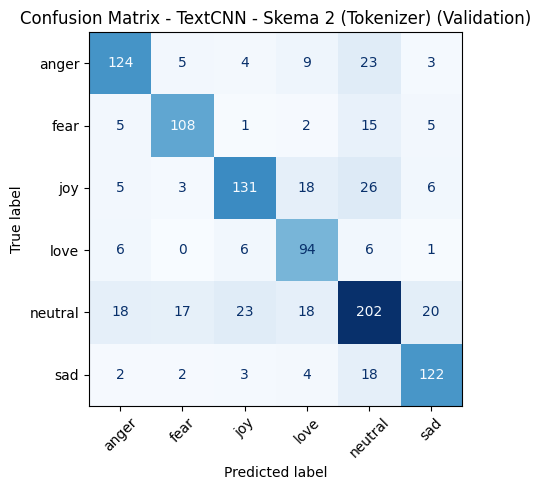

In [9]:
cm = confusion_matrix(y_val_str, y_pred_str, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - TextCNN - Skema 2 (Tokenizer) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05b_textcnn_tokenizer_confusion_matrix_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [10]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "TextCNN", "feature_extraction": "tokenizer", "split": "validation",
               "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
               "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
               "extractor": "tokenizer subword + embedding layer indobenchmark/indobert-base-p1 (beku) -> Conv1d dilatih",
               "emb_dim": int(EMB_DIM), "max_len": int(MAX_LEN), "vocab_size": int(VOCAB_SIZE),
               "epochs": EPOCHS, "n_trainable_params": int(n_params), "evaluated_epoch": "last"}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/textcnn_tokenizer_val_results.json


### Notes Part 5b:
- Vocabulary | MAX_LEN | parameter dilatih: 50000 | 128 | 923,706
- Train acc | Val acc (epoch terakhir): 0.9701 | 0.7393
- Val loss terendah di epoch: epoch ke-10 (epoch terakhir: 15)
- Accuracy | Macro-F1 (validation): 0.7440 | 0.7566
- Macro-Precision | Macro-Recall: 0.7440 | 0.7566
- F1 tertinggi | terendah per kelas: fear (0.7970) | neutral (0.6884)
- Pasangan kelas yang paling sering tertukar: joy dan neutral (46 kesalahan di dua arah)
- Test set belum disentuh.